# Problema 3 - Classificação de qualidade de vinhos com k-NN (UCI Wine Quality, arquivo winequality-red.csv, 1.599 vinhos tintos).


In [1]:
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------------------------
# Configurações gerais
# ----------------------------------------------------------------------------
BASE = Path.cwd()  # abra o notebook DENTRO da pasta do problema (ao lado de dados/)
ARQ_DADOS = BASE / "dados" / "winequality-red.csv"
PASTA_FIG = BASE / "figuras"
PASTA_FIG.mkdir(exist_ok=True)

SEED = 42
CLASSES = ["ruim", "médio", "bom"]  # índices 0, 1, 2

# Valores de k testados. Os cinco sugeridos no enunciado (1, 3, 5, 7, 11) mais
# valores maiores, para mostrar o que acontece quando k é "muito alto".
VALORES_K = [1, 3, 5, 7, 11, 15, 21, 31, 51, 101, 201, 401, 801]
K_ENUNCIADO = [1, 3, 5, 7, 11]


def titulo(texto):
    """Imprime um cabeçalho para separar as seções na saída do terminal."""
    print("\n" + "=" * 78)
    print(texto)
    print("=" * 78)


def recodificar(nota):
    """Nota <= 5 -> 0 (ruim) | 6 e 7 -> 1 (médio) | >= 8 -> 2 (bom)."""
    if nota <= 5:
        return 0
    if nota <= 7:
        return 1
    return 2

## TAREFA 1 - Preparação dos dados


TAREFA 1 - Preparação dos dados
Formato (linhas, colunas): (1599, 12)  -> 11 atributos + quality
Valores ausentes: 0
Linhas duplicadas (todas as colunas iguais): 240

Distribuição original da nota (quality):
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Distribuição das 3 classes após a recodificação:
       amostras  proporção
ruim        744     0.4653
médio       837     0.5235
bom          18     0.0113

Acurácia de um classificador que SEMPRE prevê 'médio': 52.35%

Desvio padrão de cada atributo (escalas originais):
total sulfur dioxide    32.8953
free sulfur dioxide     10.4602
fixed acidity            1.7411
residual sugar           1.4099
alcohol                  1.0657
citric acid              0.1948
volatile acidity         0.1791
sulphates                0.1695
pH                       0.1544
chlorides                0.0471
density                  0.0019
dtype: float64

Razão entre o maior e o menor desvio padrão: 17,430x


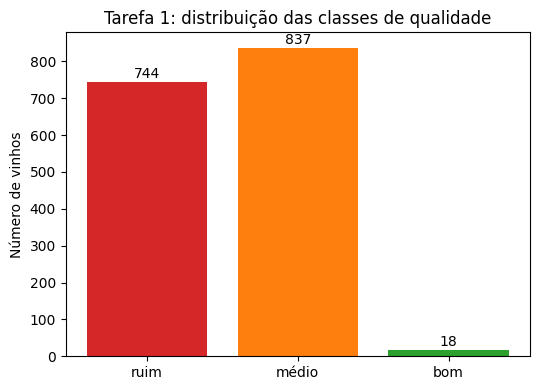

In [2]:
titulo("TAREFA 1 - Preparação dos dados")

# O arquivo da UCI usa ponto e vírgula como separador.
df = pd.read_csv(ARQ_DADOS, sep=";")
print(f"Formato (linhas, colunas): {df.shape}  -> 11 atributos + quality")
print(f"Valores ausentes: {df.isna().sum().sum()}")
print(f"Linhas duplicadas (todas as colunas iguais): {df.duplicated().sum()}")

print("\nDistribuição original da nota (quality):")
print(df["quality"].value_counts().sort_index())

# Recodificação em 3 classes (conforme o enunciado)
df["classe"] = df["quality"].apply(recodificar)
contagem = df["classe"].value_counts().sort_index()
contagem.index = CLASSES
print("\nDistribuição das 3 classes após a recodificação:")
print(pd.DataFrame({"amostras": contagem, "proporção": (contagem / len(df)).round(4)}))
print(f"\nAcurácia de um classificador que SEMPRE prevê 'médio': "
      f"{contagem['médio'] / len(df):.2%}")

FEATURES = [c for c in df.columns if c not in ("quality", "classe")]
X = df[FEATURES]
y = df["classe"]

# Escalas originais dos atributos: justificam a normalização
print("\nDesvio padrão de cada atributo (escalas originais):")
dp = X.std().sort_values(ascending=False)
print(dp.round(4))
print(f"\nRazão entre o maior e o menor desvio padrão: {dp.max() / dp.min():,.0f}x")

# Figura: distribuição das classes
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(CLASSES, contagem.values, color=["tab:red", "tab:orange", "tab:green"])
for i, v in enumerate(contagem.values):
    ax.text(i, v + 10, str(v), ha="center")
ax.set_ylabel("Número de vinhos")
ax.set_title("Tarefa 1: distribuição das classes de qualidade")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t1_distribuicao_classes.png", dpi=150)
plt.show()

# ----------------------------------------------------------------------------
# Normalização: Z-score (média 0, desvio 1), via StandardScaler.
# IMPORTANTE: o StandardScaler fica dentro de um Pipeline. Assim, em cada
# etapa (cada fold da validação cruzada e o ajuste final) a média e o desvio
# são calculados SÓ com os dados de treino daquela etapa. Normalizar o dataset
# inteiro antes de dividir faria informação do teste vazar para o treino.
# ----------------------------------------------------------------------------

## TAREFA 2 - Divisão treino/teste estratificada (80% / 20%)

In [3]:
titulo("TAREFA 2 - Divisão treino/teste estratificada (80% / 20%)")

# stratify=y garante a mesma proporção das 3 classes em treino e teste.
# Isso é essencial aqui: a classe 'bom' tem só 18 vinhos.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
tab_div = pd.DataFrame({
    "total": y.value_counts().sort_index(),
    "treino": y_treino.value_counts().sort_index(),
    "teste": y_teste.value_counts().sort_index(),
})
tab_div.index = CLASSES
tab_div["% no treino"] = (tab_div["treino"] / tab_div["treino"].sum() * 100).round(2)
tab_div["% no teste"] = (tab_div["teste"] / tab_div["teste"].sum() * 100).round(2)
print(f"Treino: {len(X_treino)} amostras | Teste: {len(X_teste)} amostras")
print(tab_div)


TAREFA 2 - Divisão treino/teste estratificada (80% / 20%)
Treino: 1279 amostras | Teste: 320 amostras
       total  treino  teste  % no treino  % no teste
ruim     744     595    149        46.52       46.56
médio    837     670    167        52.38       52.19
bom       18      14      4         1.09        1.25


## TAREFA 3 - Escolha de k por validação cruzada (5 folds) no treino


TAREFA 3 - Escolha de k (validação cruzada 5-fold no treino)
Linhas de treino: 1279 | grupos de linhas idênticas: 1119 | duplicatas no treino: 160

(A) Validação cruzada comum (StratifiedKFold) - com vazamento de duplicatas:
     acc_validação  desvio  acc_treino  F1_macro_validação
k                                                         
1           0.7256  0.0139      1.0000              0.5130
3           0.7092  0.0231      0.8483              0.4742
5           0.7131  0.0181      0.7979              0.4763
7           0.6990  0.0246      0.7799              0.4667
11          0.7139  0.0126      0.7719              0.4770
15          0.7217  0.0114      0.7596              0.4823
21          0.7115  0.0196      0.7441              0.4760
31          0.7138  0.0206      0.7324              0.4774
51          0.7248  0.0345      0.7328              0.4851
101         0.7271  0.0424      0.7273              0.4871
201         0.7021  0.0533      0.7090              0.4704
401    

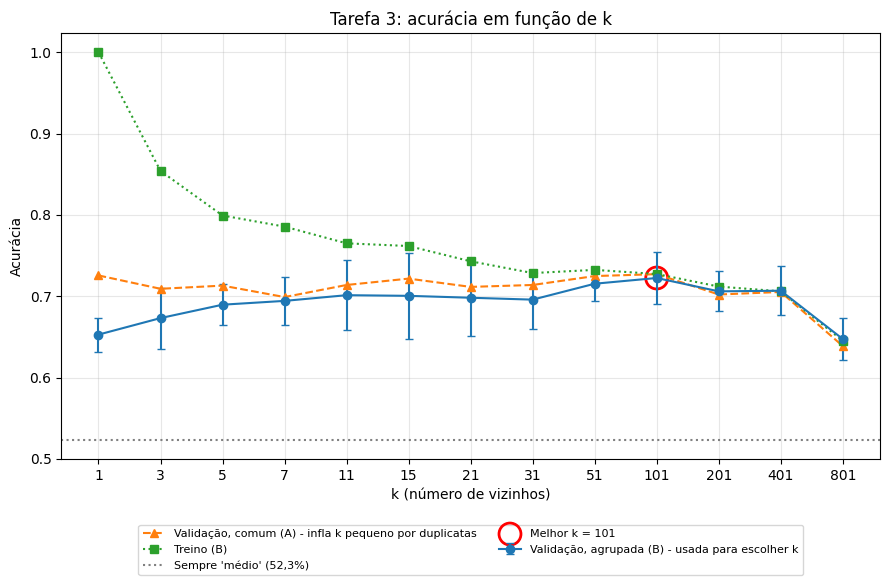

In [7]:
titulo("TAREFA 3 - Escolha de k (validação cruzada 5-fold no treino)")

# O dataset tem linhas idênticas (duplicatas). Numa validação cruzada comum,
# uma cópia pode cair no fold de validação e a outra no de treino: o k-NN a
# encontra a distância zero e "acerta por memorização", o que infla a
# acurácia (sobretudo para k pequeno). Por isso fazemos DUAS validações:
#   (A) comum:    StratifiedKFold (como pede o enunciado) - mostrada para comparação;
#   (B) agrupada: StratifiedGroupKFold - linhas idênticas ficam sempre no
#       MESMO fold. Usa os mesmos 1279 exemplos de treino, sem vazamento.
# A escolha de k é feita pela (B), que é a estimativa honesta.
cv_comum = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_agrup = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
# rótulo de grupo: linhas com todos os atributos iguais recebem o mesmo grupo
grupos = X_treino.groupby(list(X_treino.columns), sort=False).ngroup().to_numpy()
print(f"Linhas de treino: {len(X_treino)} | grupos de linhas idênticas: "
      f"{len(np.unique(grupos))} | duplicatas no treino: {len(X_treino) - len(np.unique(grupos))}")


def avaliar_k(cv, groups=None):
    """Acurácia média (validação e treino) e F1-macro para cada k."""
    linhas = []
    for k in VALORES_K:
        pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
        r = cross_validate(
            pipe, X_treino, y_treino, cv=cv, groups=groups,
            scoring=["accuracy", "f1_macro"], return_train_score=True,
        )
        linhas.append({
            "k": k,
            "acc_validação": r["test_accuracy"].mean(),
            "desvio": r["test_accuracy"].std(),
            "acc_treino": r["train_accuracy"].mean(),
            "F1_macro_validação": r["test_f1_macro"].mean(),
        })
    return pd.DataFrame(linhas).set_index("k")


tab_comum = avaliar_k(cv_comum)
tab_k = avaliar_k(cv_agrup, groups=grupos)  # tabela OFICIAL para escolher k

print("\n(A) Validação cruzada comum (StratifiedKFold) - com vazamento de duplicatas:")
print(tab_comum.round(4))
print("\n(B) Validação cruzada agrupada (StratifiedGroupKFold) - OFICIAL:")
print(tab_k.round(4))

# Melhor k = maior acurácia média de validação (empate -> menor k, que é o
# modelo mais simples/rápido). Critério pedido no enunciado: acurácia média.
melhor_acc = tab_k["acc_validação"].max()
k_melhor = int(tab_k.index[np.isclose(tab_k["acc_validação"], melhor_acc)].min())
print(f"\nMelhor k (maior acurácia média de validação, curva B): k = {k_melhor} "
      f"(acurácia = {melhor_acc:.4f})")

# Quantos valores de k ficam a menos de 1 desvio padrão do melhor?
dp_melhor = tab_k.loc[k_melhor, "desvio"]
empate = tab_k.index[tab_k["acc_validação"] >= melhor_acc - dp_melhor].tolist()
print(f"Valores de k estatisticamente próximos do melhor (dentro de 1 desvio "
      f"padrão = {dp_melhor:.4f}): {empate}")

# Melhor k entre os cinco valores sugeridos no enunciado
tab_enunc = tab_k.loc[K_ENUNCIADO, "acc_validação"]
k_melhor_enunc = int(tab_enunc.idxmax())
print(f"Melhor k entre {K_ENUNCIADO}: k = {k_melhor_enunc} "
      f"(acurácia = {tab_enunc.max():.4f})")

# Figura: acurácia média em função de k
fig, ax = plt.subplots(figsize=(9, 6))
ks = tab_k.index.to_numpy()
x = np.arange(len(ks))
ax.errorbar(x, tab_k["acc_validação"], yerr=tab_k["desvio"], marker="o", capsize=3,
            color="tab:blue", label="Validação, agrupada (B) - usada para escolher k")
ax.plot(x, tab_comum["acc_validação"], marker="^", ls="--", color="tab:orange",
        label="Validação, comum (A) - infla k pequeno por duplicatas")
ax.plot(x, tab_k["acc_treino"], marker="s", ls=":", color="tab:green",
        label="Treino (B)")
ax.axhline(contagem["médio"] / len(df), color="gray", ls=":",
           label="Sempre 'médio' (52,3%)")
ax.scatter([list(ks).index(k_melhor)], [melhor_acc], s=250, facecolors="none",
           edgecolors="red", linewidths=2, label=f"Melhor k = {k_melhor}")
ax.set_xticks(x, [str(k) for k in ks])
ax.set_xlabel("k (número de vizinhos)")
ax.set_ylabel("Acurácia")
ax.set_title("Tarefa 3: acurácia em função de k")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)  # legenda fora do gráfico
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PASTA_FIG / "t3_acuracia_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# --- Justificativa empírica da normalização ----------------------------------
# Compara a acurácia (validação cruzada) COM e SEM normalização, mesmo k.
print("\nExperimento: o efeito de normalizar (validação cruzada agrupada 5-fold, mesmo k)")
comparacao = []
for k in (k_melhor, 7, 1):
    com = cross_validate(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                         X_treino, y_treino, cv=cv_agrup, groups=grupos,
                         scoring="accuracy")["test_score"]
    sem = cross_validate(KNeighborsClassifier(n_neighbors=k),
                         X_treino, y_treino, cv=cv_agrup, groups=grupos,
                         scoring="accuracy")["test_score"]
    comparacao.append({"k": k, "COM Z-score": com.mean(), "SEM normalização": sem.mean()})
print(pd.DataFrame(comparacao).drop_duplicates("k").set_index("k").round(4))

# Contribuição de cada atributo para a distância euclidiana SEM normalizar:
# fração da variância total que cada atributo representa.
frac_var = (X_treino.var() / X_treino.var().sum()).sort_values(ascending=False)
print("\nFração da variância total por atributo (sem normalizar):")
print((frac_var * 100).round(2).astype(str) + " %")


Experimento: o efeito de normalizar (validação cruzada agrupada 5-fold, mesmo k)
     COM Z-score  SEM normalização
k                                 
101       0.7224            0.6192
7         0.6943            0.5934
1         0.6528            0.5848

Fração da variância total por atributo (sem normalizar):
total sulfur dioxide    91.08 %
free sulfur dioxide      8.44 %
fixed acidity            0.25 %
residual sugar           0.13 %
alcohol                   0.1 %
citric acid               0.0 %
volatile acidity          0.0 %
sulphates                 0.0 %
pH                        0.0 %
chlorides                 0.0 %
density                   0.0 %
dtype: str


## TAREFA 4 - Avaliação final no conjunto de teste


TAREFA 4 - Avaliação no teste (k = 101)
Acurácia no teste: 0.7344

Matriz de confusão (linhas = real, colunas = previsto):
            prev ruim  prev médio  prev bom
real ruim         111          38         0
real médio         43         124         0
real bom            0           4         0

Métricas por classe (precisão, recall, F1) + médias:
              precision    recall  f1-score   support

        ruim     0.7208    0.7450    0.7327       149
       médio     0.7470    0.7425    0.7447       167
         bom     0.0000    0.0000    0.0000         4

    accuracy                         0.7344       320
   macro avg     0.4893    0.4958    0.4925       320
weighted avg     0.7254    0.7344    0.7298       320

Erros por par (real -> previsto), em ordem decrescente:
  médio -> ruim: 43
  ruim -> médio: 38
  bom -> médio: 4

Total de erros: 85 | entre 'ruim' e 'médio': 81 (95.3% dos erros)


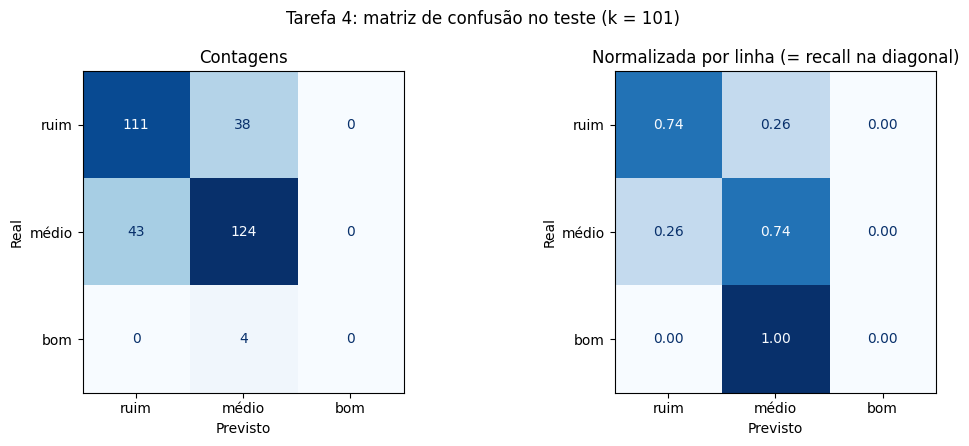

In [11]:
titulo(f"TAREFA 4 - Avaliação no teste (k = {k_melhor})")

modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_melhor))
modelo.fit(X_treino, y_treino)
prev = modelo.predict(X_teste)

print(f"Acurácia no teste: {accuracy_score(y_teste, prev):.4f}")

cm = confusion_matrix(y_teste, prev, labels=[0, 1, 2])
print("\nMatriz de confusão (linhas = real, colunas = previsto):")
print(pd.DataFrame(cm, index=[f"real {c}" for c in CLASSES],
                   columns=[f"prev {c}" for c in CLASSES]))

print("\nMétricas por classe (precisão, recall, F1) + médias:")
print(classification_report(y_teste, prev, labels=[0, 1, 2], target_names=CLASSES,
                            digits=4, zero_division=0))

# Pares de classes mais confundidos (apenas fora da diagonal)
erros = []
for i in range(3):
    for j in range(3):
        if i != j and cm[i, j] > 0:
            erros.append((CLASSES[i], CLASSES[j], int(cm[i, j])))
erros.sort(key=lambda t: t[2], reverse=True)
print("Erros por par (real -> previsto), em ordem decrescente:")
for real, previsto, n in erros:
    print(f"  {real} -> {previsto}: {n}")
n_err = int(cm.sum() - np.trace(cm))
n_ruim_medio = int(cm[0, 1] + cm[1, 0])
print(f"\nTotal de erros: {n_err} | entre 'ruim' e 'médio': {n_ruim_medio} "
      f"({n_ruim_medio / n_err:.1%} dos erros)")

# Figuras: matriz de confusão (contagens e normalizada por linha)
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=eixos[0], cmap="Blues", colorbar=False)
eixos[0].set_title("Contagens")
cm_norm = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cm_norm, display_labels=CLASSES).plot(
    ax=eixos[1], cmap="Blues", colorbar=False, values_format=".2f")
eixos[1].set_title("Normalizada por linha (= recall na diagonal)")
for ax in eixos:
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
fig.suptitle(f"Tarefa 4: matriz de confusão no teste (k = {k_melhor})")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t4_matriz_confusao.png", dpi=150)
plt.show()

## ANÁLISE COMPLEMENTAR - Duplicatas e otimismo da estimativa

O dataset tem linhas idênticas. Se uma amostra do teste tem uma cópia exata  
no treino, o k-NN a encontra a distância zero e "acerta por memorização".

In [12]:
titulo("COMPLEMENTAR - Duplicatas entre treino e teste")

chaves_treino = set(map(tuple, X_treino.round(6).to_numpy()))
tem_copia = np.array([tuple(r) in chaves_treino for r in X_teste.round(6).to_numpy()])
acerto = (prev == y_teste.to_numpy())
print(f"Amostras do teste com cópia exata no treino: {tem_copia.sum()} "
      f"de {len(X_teste)} ({tem_copia.mean():.1%})")
print(f"Acurácia nas amostras COM cópia no treino : {acerto[tem_copia].mean():.4f}")
print(f"Acurácia nas amostras SEM cópia no treino : {acerto[~tem_copia].mean():.4f}")



COMPLEMENTAR - Duplicatas entre treino e teste
Amostras do teste com cópia exata no treino: 71 de 320 (22.2%)
Acurácia nas amostras COM cópia no treino : 0.7887
Acurácia nas amostras SEM cópia no treino : 0.7189
